[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_replica_weights/BA_L3_replica_weights.ipynb)

# BA_L3_replica_weights: Market-Value Weights against Capped Weights

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Weights of the CRIX-type replica at each monthly rebalancing, April 2018 to September 2026: market-value weights and weights capped below 50% (US Patent 12,784,107 B2, claim 1).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'legend.fontsize': 8})   # as in the slide charts

## Common code

Reads the data and defines the index engine of the lecture: `index_series()` (CRIX, VCRIX), `logret()` (daily log
returns in %, only between consecutive days), `coin_panel()` (prices, USD volumes and market values
$\mathrm{MV}_{it} = P_{it}Q_{it}$ of ten coins), `laspeyres()` (market-value Laspeyres index with a divisor and optional
weight cap), the AIC rule for the number of constituents (`aic_curve`, `first_rise`, `ctdc_choice`) and the liquidity
rule `eligible()`.

In [5]:
import matplotlib
import matplotlib.dates
from scipy import stats
from scipy.optimize import least_squares
import statsmodels.api as sm

def fix_years(fig):
    # year ticks that do not overlap: every second year on narrow date axes, every year on wide ones
    for a in fig.axes:
        loc = a.xaxis.get_major_locator()
        if not isinstance(loc, matplotlib.dates.DateLocator) or isinstance(loc, matplotlib.dates.MonthLocator):
            continue
        lo, hi = a.get_xlim()
        if hi - lo < 3 * 365:
            continue
        w = a.get_position().width
        a.xaxis.set_major_locator(matplotlib.dates.YearLocator(1 if w > 0.6 else 2))
        a.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y'))


RES = {}                                   # numbers quoted on the slides
END_R = '2026-10-30'                       # last day with prices of all ten coins (EODHD)
OFFICIAL = '2018-03-16'                    # official CRIX history starts on 16 March 2018 (royalton-partners.com)
COINS = ['BTC', 'ETH', 'DOGE', 'ADA', 'LTC', 'BCH', 'ETC', 'XMR', 'DASH', 'ZEC']
CNAME = {'BTC': 'Bitcoin', 'ETH': 'Ethereum', 'DOGE': 'Dogecoin', 'ADA': 'Cardano', 'LTC': 'Litecoin',
         'BCH': 'Bitcoin Cash', 'ETC': 'Ethereum Classic', 'XMR': 'Monero', 'DASH': 'Dash', 'ZEC': 'Zcash'}
CCOL = {'BTC': BTC, 'ETH': ETH, 'DOGE': GOLD, 'ADA': GREEN, 'LTC': TEAL, 'BCH': ORANGE, 'ETC': '#556B2F',
        'XMR': RED, 'DASH': BLUE, 'ZEC': '#D63384'}


def index_series(name):
    # Royalton CRIX or VCRIX, daily (thecrix.de); missing days stay missing (NaN) on the daily calendar
    s = pd.read_csv(data_file('indices', f'{name}_daily.csv'), parse_dates=['date']).set_index('date').iloc[:, 0]
    return s.reindex(pd.date_range(s.index[0], s.index[-1]))


def logret(s):
    # daily log returns in %, only between two consecutive calendar days (a return over a data gap is dropped)
    return 100 * np.log(s).diff()


def market_file(sym):
    return pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')


def coin_panel(start='2017-06-01', end=END_R):
    # daily prices (USD), volumes (USD) and market values (billion USD = price x Coin Metrics current supply)
    days = pd.date_range(start, end)
    px, vol = {}, {}
    for c in COINS:
        d = market_file(f'{c}-USD.CC')
        d = d[d['close'] > 0]
        px[c], vol[c] = d['close'].reindex(days), d['volume'].reindex(days)
    px, vol = pd.DataFrame(px), pd.DataFrame(vol)
    sup = pd.read_csv(data_file('indices', 'coin_supply_coinmetrics.csv'), parse_dates=['date']).set_index('date')
    sup = sup[COINS].reindex(days).ffill(limit=3)
    return px, vol, sup, px * sup / 1e9


PX, VOL, SUP, MV = coin_panel()


def month_ends(start, end=END_R):
    return [d for d in pd.date_range(start, end, freq='ME')]


def laspeyres(schedule, cap=None, base=1000.0):
    # Market-value Laspeyres index with a divisor. schedule: list of (tau, members) with tau a rebalancing day; between
    # rebalancing days the quantities Q_i (supply at tau, times the cap factor AW_i) are fixed:
    #   I_t = sum_i P_it Q_i / D_tau,  D_tau chosen so that the index does not jump at tau.
    # cap: maximum weight of one constituent at tau (excess shared pro rata by the others).
    level, divisor, weights = {}, {}, {}
    I_prev, D = base, None
    for j, (tau, mem) in enumerate(schedule):
        end_ = schedule[j + 1][0] if j + 1 < len(schedule) else pd.Timestamp(END_R)
        mv0 = MV.loc[tau, mem].dropna()
        mem = list(mv0.index)
        w = mv0 / mv0.sum()
        if cap is not None and len(w) > 1:
            for _ in range(50):                 # iterate: capping one weight may push another above the cap
                over = w > cap
                if not over.any():
                    break
                excess = (w[over] - cap).sum()
                w[over] = cap
                w[~over] += excess * w[~over] / w[~over].sum()
        q = (w * mv0.sum() * 1e9 / PX.loc[tau, mem])            # quantities: capped weight x total value / price
        D = float((PX.loc[tau, mem] * q).sum() / I_prev)        # new divisor: the index level at tau is unchanged
        days = pd.date_range(tau + pd.Timedelta(days=1), end_)
        val = (PX.loc[days, mem] * q).sum(axis=1, min_count=len(mem)) / D
        for t in days:
            level[t] = val.loc[t]
        divisor[tau] = D
        weights[tau] = w
        I_prev = float(val.dropna().iloc[-1]) if val.notna().any() else I_prev
    lev = pd.Series(level).sort_index()
    lev.loc[schedule[0][0]] = base
    return lev.sort_index(), pd.Series(divisor), pd.DataFrame(weights).T.reindex(columns=COINS).fillna(0)


def ann_stats(lvl, per=365):
    # CAGR, annualised volatility of daily log returns, maximum drawdown (with dates) of an index level series
    s = lvl.dropna()
    yrs = (s.index[-1] - s.index[0]).days / 365.25
    r = logret(lvl).dropna()
    dd = s / s.cummax() - 1
    tr = dd.idxmin(); pk = s.loc[:tr].idxmax()
    return dict(start=f'{s.index[0]:%Y-%m-%d}', end=f'{s.index[-1]:%Y-%m-%d}', years=yrs, first=float(s.iloc[0]), last=float(s.iloc[-1]),
                cagr=100 * ((s.iloc[-1] / s.iloc[0]) ** (1 / yrs) - 1), vol=float(r.std() * np.sqrt(per)), n=len(r),
                mdd=100 * float(dd.min()), mdd_peak=f'{pk:%Y-%m-%d}', mdd_trough=f'{tr:%Y-%m-%d}')


# ---------- the rule for the number of constituents (Trimborn & Hardle, 2018; CTDC of US Patent 12,784,107 B2)
def rule_rows(days, mem):
    # for each day of the window: log return of the total market index (TMI, all members) and the arrays needed for
    # the candidate indices; quantities = supply at the end of the previous month, members ordered by market value
    rows = []
    for t in days:
        tau = t.to_period('M').start_time - pd.Timedelta(days=1)
        order = MV.loc[tau, mem].sort_values(ascending=False).index.tolist()
        q = SUP.loc[tau, order].values
        p1, p0 = PX.loc[t, order].values, PX.loc[t - pd.Timedelta(days=1), order].values
        if np.isfinite(p1).all() and np.isfinite(p0).all() and np.isfinite(q).all():
            rows.append((q, p1, p0))
    return rows


def resid(rows, k, beta):
    # eps_t(k, beta) = r_TMI,t - r_CRIX(k,beta),t : first coin with weight 1, the next k-1 with free weights beta
    e = np.empty(len(rows))
    for j, (q, p1, p0) in enumerate(rows):
        tot = np.log((p1 * q).sum() / (p0 * q).sum())
        w = np.concatenate([[1.0], beta, np.zeros(len(q) - k)])
        a1, a0 = (w * p1 * q).sum(), (w * p0 * q).sum()
        e[j] = tot - np.log(a1 / a0) if a1 > 0 and a0 > 0 else 1.0
    return e


def kde_loglik(base, x, loo=False):
    # log-likelihood of x under the Gaussian kernel density of the base residuals (Silverman bandwidth);
    # loo=True: leave-one-out (x is the base sample itself)
    n = len(base)
    h = 0.9 * min(base.std(ddof=1), stats.iqr(base) / 1.349) * n ** (-0.2)
    u = (x[:, None] - base[None, :]) / h
    K = np.exp(-0.5 * u ** 2) / np.sqrt(2 * np.pi)
    if loo:
        np.fill_diagonal(K, 0.0)
        f = K.sum(axis=1) / ((n - 1) * h)
    else:
        f = K.mean(axis=1) / h
    return float(np.log(np.maximum(f, 1e-300)).sum()), h


def aic_curve(days, mem, kmax=None):
    # AIC(k) = -2 log L(k) + 2 (k - 1), k = 1..kmax; L(k): the base density (k = 1, leave-one-out) at eps(k, beta_hat)
    rows = rule_rows(days, mem)
    kmax = kmax or len(mem)
    base = resid(rows, 1, np.array([]))
    ll1, h = kde_loglik(base, base, loo=True)
    aic = {1: -2 * ll1}
    for k in range(2, kmax + 1):
        fit = least_squares(lambda b: resid(rows, k, b), np.ones(k - 1), bounds=(0, np.inf))
        ll, _ = kde_loglik(base, resid(rows, k, fit.x))
        aic[k] = -2 * ll + 2 * (k - 1)
    return pd.Series(aic), len(rows), h


def first_rise(aic):
    # ECRIX rule: stop at the first k whose AIC is above that of k - 1
    ks = list(aic.index)
    for a, b in zip(ks[:-1], ks[1:]):
        if aic[b] > aic[a]:
            return a
    return ks[-1]


def ctdc_choice(curves):
    # CTDC-type rule (patent, step 8): pool the AIC curves of the last six months, fit polynomials of degree 1..dmax in k,
    # keep the degree with the lowest (Gaussian) AIC of the fit, choose the k that minimises the fitted polynomial
    k = np.concatenate([c.index.values for c in curves]).astype(float)
    y = np.concatenate([c.values for c in curves])
    kmax = int(k.max())
    best = None
    for d in range(1, min(20, kmax - 2) + 1):
        X = np.vander((k - k.mean()) / k.std(), d + 1)
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        rss = ((y - X @ b) ** 2).sum()
        a = len(y) * np.log(rss / len(y)) + 2 * (d + 1)
        if best is None or a < best[0]:
            best = (a, d, b)
    grid = np.arange(1, kmax + 1, dtype=float)
    fitted = np.vander((grid - k.mean()) / k.std(), best[1] + 1) @ best[2]
    return int(grid[np.argmin(fitted)]), best[1], pd.Series(fitted, index=grid.astype(int))


def eligible(tau, window=90):
    # liquidity rule: average daily traded volume (ADTV, USD) over the last `window` days at least the 25th percentile of
    # the ADTVs of all coins of the universe with full data in the window
    w = pd.date_range(tau - pd.Timedelta(days=window - 1), tau)
    ok = [c for c in COINS if PX.loc[w, c].notna().all() and SUP.loc[w, c].notna().all()]
    adtv = VOL.loc[w, ok].mean()
    thr = adtv.quantile(0.25)
    return [c for c in ok if adtv[c] >= thr], adtv, thr

## The replica

Quarterly reselection (31 March 2018 – 30 September 2026): liquidity rule (ADTV of the last 90 days at least the 25th
percentile), ranking by market value, number of constituents by the first rise of
$\mathrm{AIC}(k) = -2\sum_t \ln\hat f(\hat\varepsilon_t(k,\hat\beta)) + 2(k-1)$, with $\hat f$ the leave-one-out
Gaussian kernel density of the residuals of the one-coin index against the total market index (TMI); CTDC-type
choice from a polynomial fitted to six month-end AIC curves. Monthly rebalancing with new supplies and a divisor.

In [6]:
# A CRIX-style replica on the ten coins: quarterly reselection (liquidity rule + AIC rule), monthly rebalancing, divisor
qends = [d for d in pd.date_range('2018-03-31', END_R, freq='QE')]
sel = []
for qe in qends:
    elig, adtv, thr = eligible(qe)
    days = pd.date_range(qe - pd.Timedelta(days=89), qe)
    aic, n_, h_ = aic_curve(days, elig)
    order = MV.loc[qe, elig].sort_values(ascending=False).index.tolist()
    sel.append(dict(q=qe, elig=elig, n_elig=len(elig), excluded=[c for c in COINS if c not in elig], order=order, aic=aic,
                    k_ecrix=first_rise(aic), k_efcrix=int(aic.idxmin()), n=n_, h=h_, adtv_thr=thr / 1e6))
# CTDC-type choice: AIC curves at the six month-ends up to the quarter end, each on its own 90-day window, pooled
for s_ in sel:
    curves = []
    for me in [m for m in month_ends(s_['q'] - pd.Timedelta(days=170), s_['q'])]:
        elig_m, _, _ = eligible(me)
        if set(elig_m) != set(s_['elig']):
            elig_m = [c for c in s_['elig'] if c in elig_m] or s_['elig']
        c_, _, _ = aic_curve(pd.date_range(me - pd.Timedelta(days=89), me), elig_m)
        curves.append(c_)
    s_['k_ctdc'], s_['ctdc_deg'], s_['ctdc_fit'] = ctdc_choice(curves)
    s_['ctdc_curves'] = curves

# schedule: members chosen at each quarter end (top k by market value), quantities updated at every month end
def schedule_for(rule):
    sch = []
    for j, s_ in enumerate(sel):
        nxt = sel[j + 1]['q'] if j + 1 < len(sel) else pd.Timestamp(END_R)
        mem = s_['order'][:s_[rule]]
        for me in [s_['q']] + [m for m in month_ends(s_['q'] + pd.Timedelta(days=1), nxt) if m < nxt]:
            sch.append((me, mem))
    return sch


sch = schedule_for('k_ecrix')
rep, div, wts = laspeyres(sch)
rep_cap, div_cap, wts_cap = laspeyres(sch, cap=0.4999)
sch_tmi = []
for j, s_ in enumerate(sel):
    nxt = sel[j + 1]['q'] if j + 1 < len(sel) else pd.Timestamp(END_R)
    for me in [s_['q']] + [m for m in month_ends(s_['q'] + pd.Timedelta(days=1), nxt) if m < nxt]:
        sch_tmi.append((me, s_['elig']))
tmi, div_tmi, w_tmi = laspeyres(sch_tmi)
btc1, _, _ = laspeyres([(me, ['BTC']) for me, _ in sch])
ks = pd.Series({s_['q']: s_['k_ecrix'] for s_ in sel})
RES['rule'] = dict(n_q=len(sel), first=f"{sel[0]['q']:%Y-%m-%d}", last=f"{sel[-1]['q']:%Y-%m-%d}",
                   ecrix_counts={int(k): int(v) for k, v in pd.Series([s_['k_ecrix'] for s_ in sel]).value_counts().sort_index().items()},
                   efcrix_counts={int(k): int(v) for k, v in pd.Series([s_['k_efcrix'] for s_ in sel]).value_counts().sort_index().items()},
                   ctdc_counts={int(k): int(v) for k, v in pd.Series([s_['k_ctdc'] for s_ in sel]).value_counts().sort_index().items()},
                   k_mean=float(ks.mean()), k_last=int(ks.iloc[-1]), k_ctdc_last=int(sel[-1]['k_ctdc']), k_efcrix_last=int(sel[-1]['k_efcrix']),
                   n_elig_mean=float(np.mean([s_['n_elig'] for s_ in sel])),
                   last_aic={int(k): float(v) for k, v in sel[-1]['aic'].items()}, last_order=sel[-1]['order'], last_n=sel[-1]['n'],
                   last_h=sel[-1]['h'], last_excluded=sel[-1]['excluded'], last_thr_musd=sel[-1]['adtv_thr'],
                   ctdc_deg_last=int(sel[-1]['ctdc_deg']),
                   excl_counts={c: int(sum(c in s_['excluded'] for s_ in sel)) for c in COINS})
print(RES['rule'])

{'n_q': 35, 'first': '2018-03-31', 'last': '2026-09-30', 'ecrix_counts': {2: 9, 3: 13, 4: 11, 5: 1, 6: 1}, 'efcrix_counts': {2: 6, 3: 13, 4: 12, 5: 3, 6: 1}, 'ctdc_counts': {3: 30, 4: 1, 6: 1, 7: 3}, 'k_mean': 3.2, 'k_last': 4, 'k_ctdc_last': 3, 'k_efcrix_last': 4, 'n_elig_mean': 7.0, 'last_aic': {1: -662.2349247233126, 2: -946.1926029617616, 3: -953.2681077209313, 4: -953.5729049997915, 5: -952.3282788516667, 6: -950.7158431677607, 7: -948.7715001474353}, 'last_order': ['BTC', 'ETH', 'ZEC', 'DOGE', 'ADA', 'BCH', 'LTC'], 'last_n': 90, 'last_h': np.float64(0.0006854899471917494), 'last_excluded': ['ETC', 'XMR', 'DASH'], 'last_thr_musd': np.float64(130.34138708055556), 'ctdc_deg_last': 5, 'excl_counts': {'BTC': 0, 'ETH': 0, 'DOGE': 12, 'ADA': 9, 'LTC': 0, 'BCH': 0, 'ETC': 5, 'XMR': 33, 'DASH': 24, 'ZEC': 22}}


## Method

Capping: the weight above the cap is set to the cap and the excess is shared among the other constituents in
proportion to their weights, repeated until no weight exceeds the cap.

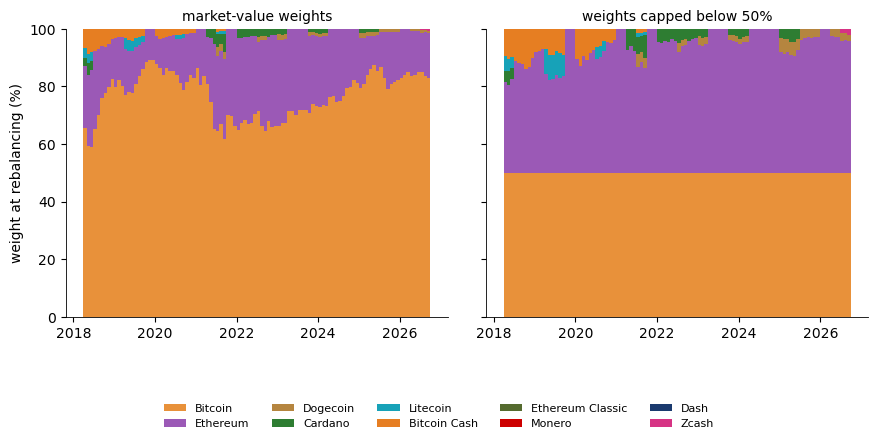

{'btc_mean': np.float64(76.85669882323691), 'btc_min': 59.122378920725126, 'btc_max': 89.26611927330976, 'btc_last': np.float64(82.07350354857749), 'eth_last': np.float64(16.018879401565496), 'cap_eth_last': np.float64(44.68827252682279), 'cap_btc_last': np.float64(49.99), 'last': {'BTC': 82.07350354857749, 'ETH': 16.018879401565496, 'DOGE': 0.7211551501933322, 'ZEC': 1.186461899663675}, 'last_cap': {'BTC': 49.99, 'ETH': 44.68827252682279, 'DOGE': 2.011824739926062, 'ZEC': 3.3099027332511506}, 'share_capped': np.float64(100.0)}


In [7]:
# Weights of the replica at each monthly rebalancing: market-value weights against weights capped below 50%
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True)
for a_, w_, t_ in [(ax[0], wts, 'market-value weights'), (ax[1], wts_cap, 'weights capped below 50%')]:
    a_.stackplot(w_.index, [100 * w_[c] for c in COINS], colors=[CCOL[c] for c in COINS], labels=[CNAME[c] for c in COINS], lw=0, step='post')
    a_.set_title(t_, fontsize=10); a_.set_ylim(0, 100)
ax[0].set_ylabel('weight at rebalancing (%)')
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=5, frameon=False); fig.tight_layout(rect=(0, 0.18, 1, 1))
fix_years(fig); save_fig(fig, 'ba_l3_replica_weights')
RES['weights'] = dict(btc_mean=100 * wts['BTC'].mean(), btc_min=100 * wts['BTC'].min(), btc_max=100 * wts['BTC'].max(),
                      btc_last=100 * wts['BTC'].iloc[-1], eth_last=100 * wts['ETH'].iloc[-1],
                      cap_eth_last=100 * wts_cap['ETH'].iloc[-1], cap_btc_last=100 * wts_cap['BTC'].iloc[-1],
                      last=dict((c, 100 * v) for c, v in wts.iloc[-1].items() if v > 0),
                      last_cap=dict((c, 100 * v) for c, v in wts_cap.iloc[-1].items() if v > 0),
                      share_capped=100 * (wts['BTC'] > 0.4999).mean())
print(RES['weights'])